# ThomasF_test

scratch work for 04-XGBoost. needs hotel_bookings.csv and hotel_bookings_clean.csv in same folder

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import xgboost as xgb
from sklearn.model_selection import train_test_split
from sklearn.metrics import log_loss, roc_auc_score, accuracy_score

df = pd.read_csv("hotel_bookings_clean.csv", keep_default_na=False, na_values=[""])
df["agent"] = df["agent"].astype(str)
df["arrival_date"] = pd.to_datetime(df["arrival_date"])
y = df.is_canceled
df.shape, y.mean()

((118558, 30), np.float64(0.3725687005516287))

In [2]:
CATS = ["hotel","arrival_date_month","meal","country","market_segment","distribution_channel",
        "reserved_room_type","deposit_type","agent","customer_type"]

# one-hot features, optional columns dropped
def feats(drop=()):
    X = df.drop(columns=["is_canceled","split","arrival_date","arrival_date_year"] + list(drop))
    return pd.get_dummies(X, columns=[c for c in CATS if c in X.columns], dtype=float)

# fit on s=='train', early stopping on s=='validation'
def fit(X, y, s, lr=0.1, **p):
    m = xgb.XGBClassifier(n_estimators=5000, learning_rate=lr, tree_method="hist", early_stopping_rounds=50,
                          eval_metric="logloss", random_state=42, n_jobs=-1, **p)
    m.fit(X[s=="train"], y[s=="train"], eval_set=[(X[s=="validation"], y[s=="validation"])], verbose=False)
    return m

# metrics on one part of split s
def score(m, X, y, s, part="test"):
    p = m.predict_proba(X[s==part], iteration_range=(0, m.best_iteration+1))[:,1]
    yy = y[s==part]
    return dict(n=len(yy), logloss=round(log_loss(yy,p),4), auc=round(roc_auc_score(yy,p),4),
                acc=round(accuracy_score(yy,p>0.5),4), mean_p=round(p.mean(),3), actual=round(yy.mean(),3))

## leakage checks

In [3]:
raw = pd.read_csv("hotel_bookings.csv")
# cancel rate for parking space / room changed at check-in
print("parking space:", raw.is_canceled[raw.required_car_parking_spaces>0].mean())
print("room changed: ", raw.is_canceled[raw.reserved_room_type!=raw.assigned_room_type].mean())

# accuracy of rule: cancelled if reservation_status_date < arrival date (kaggle notebook feature)
arr = pd.to_datetime(raw.arrival_date_year.astype(str)+"-"+raw.arrival_date_month+"-"+raw.arrival_date_day_of_month.astype(str), format="%Y-%B-%d")
rule = pd.to_datetime(raw.reservation_status_date) < arr
print("status date rule acc:", (rule==raw.is_canceled).mean())

parking space: 0.0
room changed:  0.05376416169471073
status date rule acc: 0.9825194739927967


## 1. temporal split

train < Oct 2016, val Oct-Dec 2016, test 2017

In [4]:
temporal = pd.Series(np.select([df.arrival_date < "2016-10-01", df.arrival_date < "2017-01-01"],
                               ["train","validation"], default="test"), index=df.index)
# set sizes, cancel rates, no. of months per set
print(temporal.value_counts())
print(df.groupby(temporal).is_canceled.mean())
print(df.groupby(temporal).arrival_date_month.nunique())

train         63689
test          40509
validation    14360
Name: count, dtype: int64
test          0.388309
train         0.359544
validation    0.385933
Name: is_canceled, dtype: float64


test           8
train         12
validation     3
Name: arrival_date_month, dtype: int64


In [5]:
# default params, with / without month + week number, val scores
for drop in [(), ("arrival_date_week_number",), ("arrival_date_week_number","arrival_date_month")]:
    X = feats(drop); m = fit(X, y, temporal)
    print(drop, "trees", m.best_iteration+1, score(m, X, y, temporal, "validation"))

() trees 14 {'n': 14360, 'logloss': 0.4505, 'auc': 0.8898, 'acc': 0.7863, 'mean_p': np.float32(0.311), 'actual': np.float64(0.386)}


('arrival_date_week_number',) trees 20 {'n': 14360, 'logloss': 0.4416, 'auc': 0.8909, 'acc': 0.7867, 'mean_p': np.float32(0.3), 'actual': np.float64(0.386)}


('arrival_date_week_number', 'arrival_date_month') trees 108 {'n': 14360, 'logloss': 0.4116, 'auc': 0.9043, 'acc': 0.8009, 'mean_p': np.float32(0.295), 'actual': np.float64(0.386)}


In [6]:
# tuned params from temporal random search, lr 0.03, no date features
old_p = dict(max_depth=10, min_child_weight=20, gamma=0, reg_lambda=0.131, subsample=0.713, colsample_bytree=0.647)
Xt = feats(("arrival_date_week_number","arrival_date_month"))
m_old = fit(Xt, y, temporal, lr=0.03, **old_p)
n_old = m_old.best_iteration + 1
print("trees", n_old)
print("val ", score(m_old, Xt, y, temporal, "validation"))

trees 110
val  {'n': 14360, 'logloss': 0.4072, 'auc': 0.9036, 'acc': 0.7962, 'mean_p': np.float32(0.304), 'actual': np.float64(0.386)}


In [7]:
# refit on train+val with n_old trees, score 2017 test
tv = temporal != "test"
m_old2 = xgb.XGBClassifier(n_estimators=n_old, learning_rate=0.03, tree_method="hist", random_state=42, n_jobs=-1, **old_p)
m_old2.fit(Xt[tv], y[tv])
p = m_old2.predict_proba(Xt[temporal=="test"])[:,1]; yy = y[temporal=="test"]
old_test = dict(logloss=log_loss(yy,p), auc=roc_auc_score(yy,p), acc=accuracy_score(yy,p>0.5), mean_p=p.mean(), actual=yy.mean())
old_test

{'logloss': 0.4156852662563324,
 'auc': 0.8847078344209346,
 'acc': 0.7900466562986003,
 'mean_p': np.float32(0.34559885),
 'actual': np.float64(0.38830877089041943)}

## 2. random split (from 02, copies kept together)

In [8]:
rand = df.split
# set shares and cancel rates
print(rand.value_counts(normalize=True).round(3))
print(df.groupby(rand).is_canceled.mean())

# default params, with / without month + week number, val scores
for drop in [(), ("arrival_date_week_number",), ("arrival_date_week_number","arrival_date_month")]:
    X = feats(drop); m = fit(X, y, rand)
    print(drop, "trees", m.best_iteration+1, score(m, X, y, rand, "validation"))

split
train         0.703
test          0.151
validation    0.146
Name: proportion, dtype: float64
split
test          0.367536
train         0.373122
validation    0.375108
Name: is_canceled, dtype: float64


() trees 271 {'n': 17331, 'logloss': 0.3304, 'auc': 0.922, 'acc': 0.8435, 'mean_p': np.float32(0.371), 'actual': np.float64(0.375)}


('arrival_date_week_number',) trees 288 {'n': 17331, 'logloss': 0.3331, 'auc': 0.9205, 'acc': 0.8424, 'mean_p': np.float32(0.37), 'actual': np.float64(0.375)}


('arrival_date_week_number', 'arrival_date_month') trees 256 {'n': 17331, 'logloss': 0.3357, 'auc': 0.9191, 'acc': 0.8395, 'mean_p': np.float32(0.369), 'actual': np.float64(0.375)}


In [9]:
# final params from 04, lr 0.03, all features, test scores
new_p = dict(max_depth=10, min_child_weight=5, gamma=0.5, reg_lambda=7.137, subsample=0.858, colsample_bytree=0.911)
X = feats()
m_new = fit(X, y, rand, lr=0.03, **new_p)
print("trees", m_new.best_iteration+1)
new_test = score(m_new, X, y, rand, "test")
new_test

trees 728


{'n': 17903,
 'logloss': 0.3104,
 'auc': 0.9305,
 'acc': 0.8511,
 'mean_p': np.float32(0.367),
 'actual': np.float64(0.368)}

In [10]:
# temporal vs random test scores
cmp = pd.DataFrame({"temporal (old)": old_test, "random (new)": {k: new_test[k] for k in old_test}}).round(4)
cmp

,temporal (old),random (new)
logloss,0.4157,0.3104
auc,0.8847,0.9305
acc,0.7900,0.8511
mean_p,0.3456,0.3670
actual,0.3883,0.3680


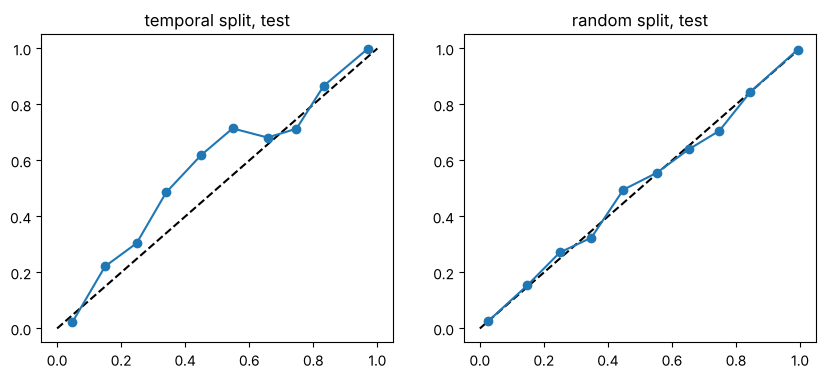

In [11]:
# reliability plots, test set, both splits
fig, ax = plt.subplots(1, 2, figsize=(10,4))
for a, (name, mdl, XX, s) in zip(ax, [("temporal", m_old2, Xt, temporal), ("random", m_new, X, rand)]):
    pp = mdl.predict_proba(XX[s=="test"])[:,1]; yy = y[s=="test"]
    b = pd.cut(pp, np.linspace(0,1,11), include_lowest=True)
    t = pd.DataFrame({"p":pp,"y":yy.values}).groupby(b, observed=True).mean()
    a.plot([0,1],[0,1],"k--"); a.plot(t.p, t.y, "o-"); a.set_title(name + " split, test")
plt.show()

## 3. duplicates

In [12]:
dup = df.drop(columns=["split"]).duplicated(keep=False)
# share of duplicate rows, cancel rates dup vs non-dup, cancel rate after dropping dups
print("copy of an earlier row:", df.drop(columns=["split"]).duplicated().mean().round(3))
print("in a group of identical rows:", dup.mean().round(3))
print("cancel rate dup / non-dup:", y[dup].mean().round(3), y[~dup].mean().round(3))
print("cancel rate dups dropped:", y[~df.drop(columns=['split']).duplicated()].mean().round(3))

copy of an earlier row: 0.289
in a group of identical rows: 0.361
cancel rate dup / non-dup: 0.559 0.267
cancel rate dups dropped: 0.279


In [13]:
key = pd.util.hash_pandas_object(df.drop(columns=["split"]), index=False)

# stratified random 70/15/15 split of given row index
def rsplit(idx, seed=42):
    tr, rest = train_test_split(idx, test_size=0.30, stratify=y[idx], random_state=seed)
    va, te = train_test_split(rest, test_size=0.50, stratify=y[rest], random_state=seed)
    s = pd.Series("drop", index=df.index); s[tr] = "train"; s[va] = "validation"; s[te] = "test"
    return s

# share of test rows with an identical row in train
plain = rsplit(df.index)
print("plain split:", key[plain=="test"].isin(set(key[plain=="train"])).mean().round(3))
print("our split:  ", key[rand=="test"].isin(set(key[rand=="train"])).mean())

plain split: 0.329
our split:   0.0


In [14]:
# test scores, final params at lr 0.1: A grouped split, B plain split, C dups removed
X = feats()
keep = ~df.drop(columns=["split"]).duplicated()
nodup = rsplit(df.index[keep])
res = {}
for name, s in [("A copies kept together (ours)", rand), ("B plain random split", plain), ("C duplicates removed", nodup)]:
    res[name] = score(fit(X, y, s, **new_p), X, y, s, "test")
pd.DataFrame(res).T

,n,logloss,auc,acc,mean_p,actual
A copies kept together (ours),17903.0,0.3134,0.9290,0.8465,0.367,0.368
B plain random split,17784.0,0.2821,0.9451,0.8720,0.368,0.373
C duplicates removed,12652.0,0.3612,0.8910,0.8285,0.276,0.279


## 4. other checks

In [15]:
# default vs tuned params, val scores
X = feats()
print("default:", score(fit(X, y, rand), X, y, rand, "validation"))
print("tuned:  ", score(m_new, X, y, rand, "validation"))

default: {'n': 17331, 'logloss': 0.3304, 'auc': 0.922, 'acc': 0.8435, 'mean_p': np.float32(0.371), 'actual': np.float64(0.375)}


tuned:   {'n': 17331, 'logloss': 0.3198, 'auc': 0.9275, 'acc': 0.8484, 'mean_p': np.float32(0.37), 'actual': np.float64(0.375)}


In [16]:
# scale_pos_weight = neg/pos vs unweighted, val scores
w = (y[rand=="train"]==0).sum() / (y[rand=="train"]==1).sum()
m_w = fit(X, y, rand, scale_pos_weight=w, **new_p)
print("weight", round(w,2))
print("unweighted:", score(fit(X, y, rand, **new_p), X, y, rand, "validation"))
print("weighted:  ", score(m_w, X, y, rand, "validation"))

weight 1.68


unweighted: {'n': 17331, 'logloss': 0.3217, 'auc': 0.9265, 'acc': 0.8467, 'mean_p': np.float32(0.37), 'actual': np.float64(0.375)}
weighted:   {'n': 17331, 'logloss': 0.331, 'auc': 0.926, 'acc': 0.8427, 'mean_p': np.float32(0.415), 'actual': np.float64(0.375)}
